# Store Session Security Monitor: intrusion detection with an MLP

**Scenario.** An online store's security admin monitors login sessions on the store, from customers and staff.
Each session is scored by the model for intrusion risk (Low / Medium / High). The admin dashboard then suggests the likely
threat pattern (brute force, known-bad source, automated bot) and preventive actions, using fixed rules on the session's values.

**Dataset.** Kaggle `dnkumars/cybersecurity-intrusion-detection-dataset`: 9,537 sessions, 9 features, binary target `attack_detected`.

**Part 1** loads the raw file untouched and prepares it step by step (every step is visible, with before/after output), then splits and encodes it.
The raw file is never modified, so every run repeats the whole preparation from the raw rows.
**Part 2** builds and trains one model, a PyTorch multi-layer perceptron (MLP), evaluates it once on the test set and exports it for the web services.

## 1. Setup
Fixed seed 42 everywhere so the run is reproducible. The notebook runs from `notebooks/`, so the project root is added to the path
to import the shared `intrusion` package (the same code the services use).

In [1]:
import sys
import random
import warnings

sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from intrusion.data import (
    raw_path, file_sha256, load_raw, quality_report,
    fill_missing_encryption, drop_identifier, clean, split, TARGET,
)
from intrusion.preprocess import build_preprocessor, feature_names, NUMERIC, ORIGINAL_FEATURES

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
%matplotlib inline
print("setup done, seed =", SEED)

setup done, seed = 42


## 2. Raw data, untouched
The raw CSV stays in the kagglehub cache and is only ever *read*. Its SHA-256 hash (a fingerprint of the file) is printed so any change
to the source data would be visible. Everything below works on in-memory copies.

In [2]:
path = raw_path()
raw_hash = file_sha256(path)
raw = load_raw(path)
print("path   :", path)
print("sha256 :", raw_hash)
print("shape  :", raw.shape)
print()
print(raw.dtypes)
raw.head()

path   : C:\Users\meiri\.cache\kagglehub\datasets\dnkumars\cybersecurity-intrusion-detection-dataset\versions\2\cybersecurity_intrusion_data.csv
sha256 : ef92832692c7ad45225d38f637a6a5c2d26d39a10157654b6c56c61a7850d0f7
shape  : (9537, 11)

session_id              object
network_packet_size      int64
protocol_type           object
login_attempts           int64
session_duration       float64
encryption_used         object
ip_reputation_score    float64
failed_logins            int64
browser_type            object
unusual_time_access      int64
attack_detected          int64
dtype: object


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


## 3. Data-quality report
Before changing anything we measure what is wrong with the data: missing values (a model cannot ingest NaN),
duplicate rows (would leak between splits), numeric ranges (to spot impossible values) and logical inconsistencies.
Rows where `failed_logins > login_attempts` are logically odd (you cannot fail more logins than you attempt).
We *report* them but keep them, because the live API must accept the same kind of rows the data contains.

In [3]:
report = quality_report(raw)
print("rows       :", report["rows"])
print("duplicates :", report["duplicates"])
print("rows with failed_logins > login_attempts:", report["failed_gt_attempts"])
print("\nMissing values per column:")
display(pd.Series(report["missing"], name="missing").to_frame())
print("Numeric ranges:")
display(pd.DataFrame(report["ranges"], index=["min", "max"]).T)
print("Five of the rows where failed_logins > login_attempts:")
display(raw[raw["failed_logins"] > raw["login_attempts"]].head(5))

rows       : 9537
duplicates : 0
rows with failed_logins > login_attempts: 730

Missing values per column:


,missing
encryption_used,1966


Numeric ranges:


,min,max
network_packet_size,64.000000,1285.000000
login_attempts,1.000000,13.000000
session_duration,0.500000,7190.392213
ip_reputation_score,0.002497,0.924299
failed_logins,0.000000,5.000000
unusual_time_access,0.000000,1.000000
attack_detected,0.000000,1.000000


Five of the rows where failed_logins > login_attempts:


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
17,SID_00018,562,UDP,1,87.641002,NaN,0.136729,2,Firefox,0,0
33,SID_00034,288,ICMP,2,1039.101186,AES,0.110269,3,Chrome,0,1
59,SID_00060,695,UDP,1,989.889796,AES,0.259419,2,Edge,0,1
69,SID_00070,370,TCP,1,1105.380602,AES,0.408654,2,Chrome,0,1
101,SID_00102,415,TCP,2,294.584967,AES,0.204681,3,Chrome,0,1


**Findings.** Only `encryption_used` has missing values; in this dataset a missing value means no encryption was used, so it is a real category
rather than an unknown. There are no duplicates and the numeric ranges are plausible. The `failed_logins > login_attempts` rows are
a data-quality quirk of this synthetic dataset, noted and kept.

## 4. Cleaning, one step per cell
### 4.1 Missing `encryption_used` becomes the category `"None"`
A missing value here means "no encryption". Encoding it as its own category keeps all 1,966 rows and lets the model use the information.

In [4]:
before = raw["encryption_used"].value_counts(dropna=False)
step1 = fill_missing_encryption(raw)
after = step1["encryption_used"].value_counts(dropna=False)
display(pd.concat([before.rename("before"), after.rename("after")], axis=1).fillna(0).astype(int))
print("NaN before:", raw["encryption_used"].isna().sum(), "| NaN after:", step1["encryption_used"].isna().sum())

,before,after
encryption_used,,
AES,4706,4706
DES,2865,2865
NaN,1966,0
None,0,1966


NaN before: 1966 | NaN after: 0


### 4.2 Drop the identifier `session_id`
`session_id` is a unique label with no predictive meaning. Left in, a model could memorise it, and it would be one-hot-encoded into thousands of useless columns.

In [5]:
step2 = drop_identifier(step1)
print("columns before:", list(step1.columns))
print("columns after :", list(step2.columns))
print("shape before -> after:", step1.shape, "->", step2.shape)

columns before: ['session_id', 'network_packet_size', 'protocol_type', 'login_attempts', 'session_duration', 'encryption_used', 'ip_reputation_score', 'failed_logins', 'browser_type', 'unusual_time_access', 'attack_detected']
columns after : ['network_packet_size', 'protocol_type', 'login_attempts', 'session_duration', 'encryption_used', 'ip_reputation_score', 'failed_logins', 'browser_type', 'unusual_time_access', 'attack_detected']
shape before -> after: (9537, 11) -> (9537, 10)


### 4.3 The full pipeline, and proof that the raw frame is untouched
`clean` chains both steps and returns a **new** DataFrame. The assertions show the original `raw` frame still has its NaNs and its `session_id`.

In [6]:
df = clean(raw)
assert raw["encryption_used"].isna().sum() > 0, "raw lost its NaNs"
assert "session_id" in raw.columns, "raw lost session_id"
assert df["encryption_used"].isna().sum() == 0 and "session_id" not in df.columns
print("raw :", raw.shape, "| NaNs in encryption_used:", raw["encryption_used"].isna().sum(), "| has session_id:", "session_id" in raw.columns)
print("df  :", df.shape, "| NaNs in encryption_used:", df["encryption_used"].isna().sum(), "| has session_id:", "session_id" in df.columns)
print("Assertions passed: cleaning created a new frame and left the raw one unchanged.")
df.head()

raw : (9537, 11) | NaNs in encryption_used: 1966 | has session_id: True
df  : (9537, 10) | NaNs in encryption_used: 0 | has session_id: False
Assertions passed: cleaning created a new frame and left the raw one unchanged.


,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


## 5. Split (stratified 70 / 15 / 15)
The split comes *before* any fitting, so the validation and test sets stay unseen.
It is stratified on the target so every split keeps the same attack rate. Train is used to fit, validation to stop training, test only for the final evaluation.

In [7]:
train_df, val_df, test_df = split(df)
pd.DataFrame(
    {
        "rows": [len(train_df), len(val_df), len(test_df)],
        "share": [len(d) / len(df) for d in (train_df, val_df, test_df)],
        "attack_rate": [d[TARGET].mean() for d in (train_df, val_df, test_df)],
    },
    index=["train", "val", "test"],
).round(4)

,rows,share,attack_rate
train,6675,0.6999,0.4470
val,1431,0.1500,0.4472
test,1431,0.1500,0.4472


## 6. Class balance
Checked on the training split only, so nothing about the validation or test data influences our choices.

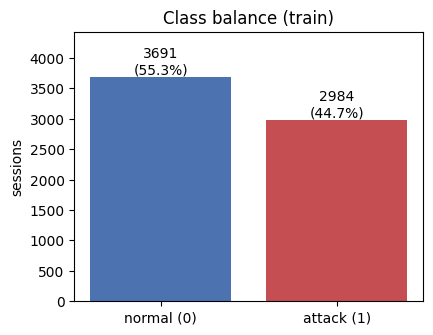

In [8]:
counts = train_df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(["normal (0)", "attack (1)"], counts.values, color=["#4c72b0", "#c44e52"])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylabel("sessions")
ax.set_title("Class balance (train)")
ax.set_ylim(0, counts.max() * 1.2)
plt.show()

The classes are close to balanced (about 45% attacks), so accuracy is a fair headline metric and no resampling is needed. We still report precision, recall, F1 and AUC.

## 7. Encode and scale
A neural network needs numeric inputs on comparable scales. A `ColumnTransformer` standardises the 6 numeric columns (mean 0, std 1)
and one-hot encodes the 3 categoricals (protocol, encryption, browser) with a fixed category order, giving 17 features.
It is **fitted on the training split only** and then applied to validation and test, so no test statistics leak into training.

In [9]:
pre = build_preprocessor()
X_train = pre.fit_transform(train_df[ORIGINAL_FEATURES]).astype(np.float32)
X_val = pre.transform(val_df[ORIGINAL_FEATURES]).astype(np.float32)
X_test = pre.transform(test_df[ORIGINAL_FEATURES]).astype(np.float32)
y_train = train_df[TARGET].to_numpy(dtype=np.float32)
y_val = val_df[TARGET].to_numpy(dtype=np.float32)
y_test = test_df[TARGET].to_numpy(dtype=np.float32)
FEATS = feature_names(pre)

print(f"{len(FEATS)} features:", FEATS)
print("X_train", X_train.shape, "X_val", X_val.shape, "X_test", X_test.shape)
print("y_train", y_train.shape, "y_val", y_val.shape, "y_test", y_test.shape)
print("\nScaled numeric columns in train (mean should be ~0, std ~1):")
display(pd.DataFrame(X_train[:, :len(NUMERIC)], columns=FEATS[:len(NUMERIC)]).agg(["mean", "std"]).round(4))
print("First 3 encoded training rows:")
display(pd.DataFrame(X_train[:3], columns=FEATS).round(3))

17 features: ['num__network_packet_size', 'num__login_attempts', 'num__session_duration', 'num__ip_reputation_score', 'num__failed_logins', 'num__unusual_time_access', 'cat__protocol_type_ICMP', 'cat__protocol_type_TCP', 'cat__protocol_type_UDP', 'cat__encryption_used_AES', 'cat__encryption_used_DES', 'cat__encryption_used_None', 'cat__browser_type_Chrome', 'cat__browser_type_Edge', 'cat__browser_type_Firefox', 'cat__browser_type_Safari', 'cat__browser_type_Unknown']
X_train (6675, 17) X_val (1431, 17) X_test (1431, 17)
y_train (6675,) y_val (1431,) y_test (1431,)

Scaled numeric columns in train (mean should be ~0, std ~1):


,num__network_packet_size,num__login_attempts,num__session_duration,num__ip_reputation_score,num__failed_logins,num__unusual_time_access
mean,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000
std,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001


First 3 encoded training rows:


,num__network_packet_size,num__login_attempts,num__session_duration,num__ip_reputation_score,num__failed_logins,num__unusual_time_access,cat__protocol_type_ICMP,cat__protocol_type_TCP,cat__protocol_type_UDP,cat__encryption_used_AES,cat__encryption_used_DES,cat__encryption_used_None,cat__browser_type_Chrome,cat__browser_type_Edge,cat__browser_type_Firefox,cat__browser_type_Safari,cat__browser_type_Unknown
0,-0.694,-0.022,-0.987,0.364,-0.502,2.360,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.240,0.984,1.561,-1.476,0.465,2.360,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2.007,0.984,-0.635,0.136,-1.469,-0.424,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


# Part 2: the PyTorch MLP

Part 2 trains the model, a multi-layer perceptron, with a hand-written training loop. Every epoch logs train and validation
metrics, early stopping watches the validation loss, and the best weights are restored. The model is then evaluated once on the test set
and exported for the web services.

## 8. Model architecture
The architecture is printed in full below; the metric function (section 10), early stopping (section 11) and the hand-written training loop (section 12) are
written out in this notebook. The `MLP` class is imported from `intrusion/model.py` so the notebook and both services run identical code.
Two hidden layers (64 and 32 units) are plenty for 17 inputs; BatchNorm stabilises training and Dropout(0.2) limits overfitting.
The last layer outputs one **logit**; the sigmoid is applied only at inference, because `BCEWithLogitsLoss` is numerically more stable on logits.

In [10]:
import copy
import inspect
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, confusion_matrix, ConfusionMatrixDisplay

from intrusion.model import MLP
from intrusion.inference import save_artifacts, Predictor
from intrusion.preprocess import Session

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ARTIFACTS = Path("../artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("device:", device)
print(inspect.getsource(MLP))

device: cuda
class MLP(nn.Module):
    """Multi-layer perceptron for binary intrusion detection."""

    def __init__(self, in_features: int = 17):
        """Initialize the MLP with the specified input features.

        Args:
            in_features: Number of input features (default 17).
        """
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1),
        )

    def forward(self, x: Tensor) -> Tensor:
        """Forward pass through the network.

        Args:
            x: Input tensor of shape [B, 17] where B is batch size.

        Returns:
            Logits of shape [B] (squeezed from [B, 1]).
        """
        out = self.net(x)
        return out.squeeze(-1)



## 9. DataLoaders
The encoded arrays become tensors. The training loader feeds the model shuffled mini-batches of 64 sessions every epoch, using its own generator
seeded 42 so the batch order is reproducible. Validation and test are evaluated in one pass each, so they need no loader.

In [11]:
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(SEED))
xb, yb = next(iter(train_loader))
print("train batches per epoch:", len(train_loader))
print("one batch: X", tuple(xb.shape), xb.dtype, "| y", tuple(yb.shape), yb.dtype)

train batches per epoch: 105
one batch: X (64, 17) torch.float32 | y (64,) torch.float32


## 10. Metric function
One function computes every metric we log (accuracy, precision, recall, F1, AUC), so train, validation and test are measured identically.
Probabilities are thresholded at 0.5 for the class metrics; AUC uses the raw probabilities. `zero_division=0` avoids warnings in the first epochs when
the model may predict only one class.

In [12]:
def compute_metrics(y_true, prob, threshold=0.5) -> dict:
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc": roc_auc_score(y_true, prob),
    }

print(compute_metrics([0, 1, 1, 0], [0.2, 0.9, 0.4, 0.1]))

{'accuracy': 0.75, 'precision': 1.0, 'recall': 0.5, 'f1': 0.6666666666666666, 'auc': 1.0}


## 11. Early stopping
Training for a fixed number of epochs risks overfitting. `EarlyStopping` watches the validation loss: an epoch counts as an improvement only if the loss drops by more
than `min_delta`. It keeps a deep copy of the best weights, and after `patience` epochs without improvement it signals the loop to stop.

In [13]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.best_epoch = 0
        self.best_state = None
        self.counter = 0
        self.epoch = 0

    def step(self, val_loss, model) -> bool:
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_epoch = self.epoch
            self.best_state = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
        return self.counter >= self.patience

## 12. Training loop
Each epoch: one training pass over shuffled mini-batches (dropout and batch-norm in training mode), then the model is switched to eval mode
and the loss and all metrics are computed on the full train and validation sets. Each epoch prints one row and is stored in `history`.
Loss `BCEWithLogitsLoss`, Adam (lr 1e-3, weight decay 1e-4), at most 200 epochs, early stopping with patience 10 on validation loss.

In [14]:
model = MLP(in_features=X_train.shape[1]).to(device)
print(model)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
es = EarlyStopping(patience=10, min_delta=1e-4)
MAX_EPOCHS = 200


def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X).to(device))
        loss = criterion(logits, torch.from_numpy(y).to(device)).item()
        prob = torch.sigmoid(logits).cpu().numpy()
    return loss, compute_metrics(y, prob)


history = []
for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

    tr_loss, tr = evaluate(model, X_train, y_train)
    va_loss, va = evaluate(model, X_val, y_val)
    row = {"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss}
    row.update({f"train_{k}": v for k, v in tr.items()})
    row.update({f"val_{k}": v for k, v in va.items()})
    history.append(row)
    print(f"epoch {epoch:3d} | loss {tr_loss:.4f}/{va_loss:.4f} | acc {tr['accuracy']:.4f}/{va['accuracy']:.4f} | "
          f"prec {tr['precision']:.4f}/{va['precision']:.4f} | rec {tr['recall']:.4f}/{va['recall']:.4f} | "
          f"f1 {tr['f1']:.4f}/{va['f1']:.4f} | auc {tr['auc']:.4f}/{va['auc']:.4f}  (train/val)")

    if es.step(va_loss, model):
        print(f"Early stopping at epoch {epoch} (best epoch {es.best_epoch})")
        break

model.load_state_dict(es.best_state)
model.eval()
hist = pd.DataFrame(history)
hist.to_csv(ARTIFACTS / "metrics.csv", index=False)
print(f"Restored best weights from epoch {es.best_epoch} (val loss {es.best_loss:.4f}); {len(hist)} epochs saved to {ARTIFACTS / 'metrics.csv'}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=17, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


epoch   1 | loss 0.4677/0.4951 | acc 0.7897/0.7722 | prec 0.7788/0.7549 | rec 0.7396/0.7266 | f1 0.7587/0.7404 | auc 0.8537/0.8293  (train/val)
epoch   2 | loss 0.4036/0.4268 | acc 0.8348/0.8267 | prec 0.8577/0.8538 | rec 0.7557/0.7391 | f1 0.8035/0.7923 | auc 0.8806/0.8619  (train/val)


epoch   3 | loss 0.3724/0.3989 | acc 0.8584/0.8449 | prec 0.9311/0.9231 | rec 0.7379/0.7125 | f1 0.8233/0.8042 | auc 0.8859/0.8670  (train/val)
epoch   4 | loss 0.3593/0.3876 | acc 0.8715/0.8581 | prec 0.9547/0.9524 | rec 0.7480/0.7188 | f1 0.8388/0.8192 | auc 0.8905/0.8706  (train/val)


epoch   5 | loss 0.3480/0.3776 | acc 0.8736/0.8574 | prec 0.9455/0.9395 | rec 0.7611/0.7281 | f1 0.8433/0.8204 | auc 0.8913/0.8713  (train/val)
epoch   6 | loss 0.3407/0.3706 | acc 0.8785/0.8686 | prec 0.9653/0.9689 | rec 0.7554/0.7297 | f1 0.8475/0.8324 | auc 0.8938/0.8738  (train/val)


epoch   7 | loss 0.3372/0.3686 | acc 0.8825/0.8679 | prec 0.9820/0.9788 | rec 0.7510/0.7203 | f1 0.8511/0.8299 | auc 0.8958/0.8741  (train/val)
epoch   8 | loss 0.3286/0.3583 | acc 0.8830/0.8658 | prec 0.9554/0.9462 | rec 0.7745/0.7422 | f1 0.8555/0.8319 | auc 0.8963/0.8746  (train/val)


...

epoch  55 | loss 0.2849/0.3311 | acc 0.8966/0.8805 | prec 0.9957/0.9875 | rec 0.7721/0.7422 | f1 0.8698/0.8475 | auc 0.9230/0.8704  (train/val)
epoch  56 | loss 0.2838/0.3300 | acc 0.8969/0.8798 | prec 0.9944/0.9815 | rec 0.7738/0.7453 | f1 0.8703/0.8472 | auc 0.9206/0.8724  (train/val)


epoch  57 | loss 0.2855/0.3319 | acc 0.8974/0.8819 | prec 0.9965/0.9916 | rec 0.7731/0.7422 | f1 0.8707/0.8490 | auc 0.9229/0.8727  (train/val)
epoch  58 | loss 0.2826/0.3346 | acc 0.8975/0.8728 | prec 0.9889/0.9617 | rec 0.7795/0.7453 | f1 0.8718/0.8398 | auc 0.9215/0.8702  (train/val)


epoch  59 | loss 0.2824/0.3326 | acc 0.8975/0.8840 | prec 0.9957/0.9917 | rec 0.7741/0.7469 | f1 0.8710/0.8520 | auc 0.9226/0.8696  (train/val)
epoch  60 | loss 0.2856/0.3348 | acc 0.8963/0.8826 | prec 0.9957/0.9937 | rec 0.7714/0.7422 | f1 0.8693/0.8497 | auc 0.9243/0.8671  (train/val)


epoch  61 | loss 0.2882/0.3363 | acc 0.8948/0.8791 | prec 0.9974/0.9958 | rec 0.7668/0.7328 | f1 0.8670/0.8443 | auc 0.9232/0.8659  (train/val)
epoch  62 | loss 0.2778/0.3302 | acc 0.8971/0.8791 | prec 0.9877/0.9736 | rec 0.7795/0.7500 | f1 0.8713/0.8473 | auc 0.9220/0.8702  (train/val)


epoch  63 | loss 0.2809/0.3301 | acc 0.8974/0.8826 | prec 0.9957/0.9896 | rec 0.7738/0.7453 | f1 0.8708/0.8503 | auc 0.9243/0.8708  (train/val)
epoch  64 | loss 0.2841/0.3372 | acc 0.8954/0.8791 | prec 0.9922/0.9854 | rec 0.7721/0.7406 | f1 0.8685/0.8457 | auc 0.9249/0.8681  (train/val)
Early stopping at epoch 64 (best epoch 54)
Restored best weights from epoch 54 (val loss 0.3274); 64 epochs saved to ..\artifacts\metrics.csv


## 13. Training curves
### 13.1 Loss
The dashed line marks the best epoch, whose weights were restored. After it, the validation loss stops improving while training continues for `patience` epochs.

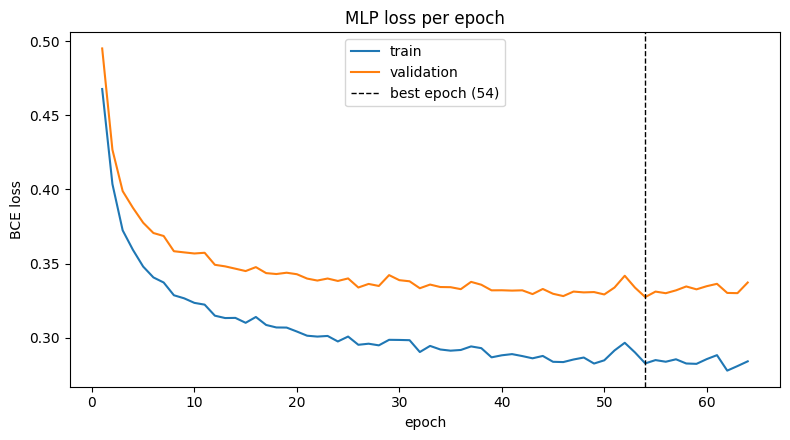

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(hist["epoch"], hist["train_loss"], label="train")
ax.plot(hist["epoch"], hist["val_loss"], label="validation")
ax.axvline(es.best_epoch, color="k", ls="--", lw=1, label=f"best epoch ({es.best_epoch})")
ax.set_xlabel("epoch")
ax.set_ylabel("BCE loss")
ax.set_title("MLP loss per epoch")
ax.legend()
fig.tight_layout()
plt.show()

### 13.2 Metrics per epoch
Accuracy, precision, recall, F1 and AUC for train and validation, with the same best-epoch marker. The sixth panel shows the generalisation gap
(validation minus train accuracy).

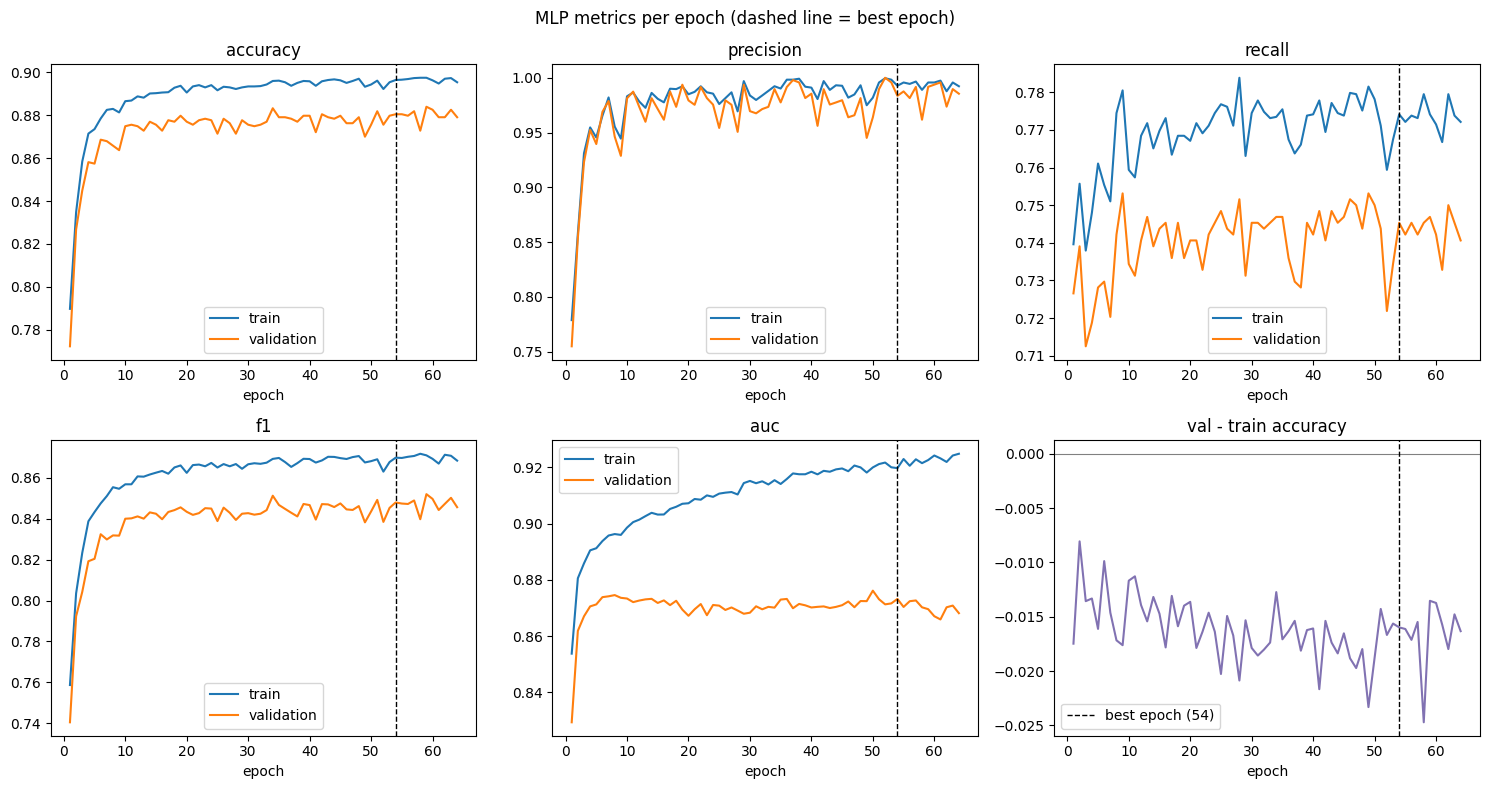

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.ravel(), ["accuracy", "precision", "recall", "f1", "auc"]):
    ax.plot(hist["epoch"], hist[f"train_{m}"], label="train")
    ax.plot(hist["epoch"], hist[f"val_{m}"], label="validation")
    ax.axvline(es.best_epoch, color="k", ls="--", lw=1)
    ax.set_title(m)
    ax.set_xlabel("epoch")
    ax.legend()
ax = axes.ravel()[5]
ax.plot(hist["epoch"], hist["val_accuracy"] - hist["train_accuracy"], color="#8172b2")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(es.best_epoch, color="k", ls="--", lw=1, label=f"best epoch ({es.best_epoch})")
ax.set_title("val - train accuracy")
ax.set_xlabel("epoch")
ax.legend()
fig.suptitle("MLP metrics per epoch (dashed line = best epoch)")
fig.tight_layout()
plt.show()

## 14. Final test evaluation (run once)
The test set has not been touched until now. The MLP (best weights) is scored once.

In [17]:
with torch.no_grad():
    mlp_prob = torch.sigmoid(model(torch.from_numpy(X_test).to(device))).cpu().numpy()
mlp_pred = (mlp_prob >= 0.5).astype(int)
pd.DataFrame({"MLP (test)": compute_metrics(y_test, mlp_prob)}).T.round(4)

,accuracy,precision,recall,f1,auc
MLP (test),0.8812,0.9896,0.7422,0.8482,0.8794


### 14.1 ROC curve
The ROC curve shows the true-positive rate against the false-positive rate across all thresholds; the area under it (AUC) is threshold-free.

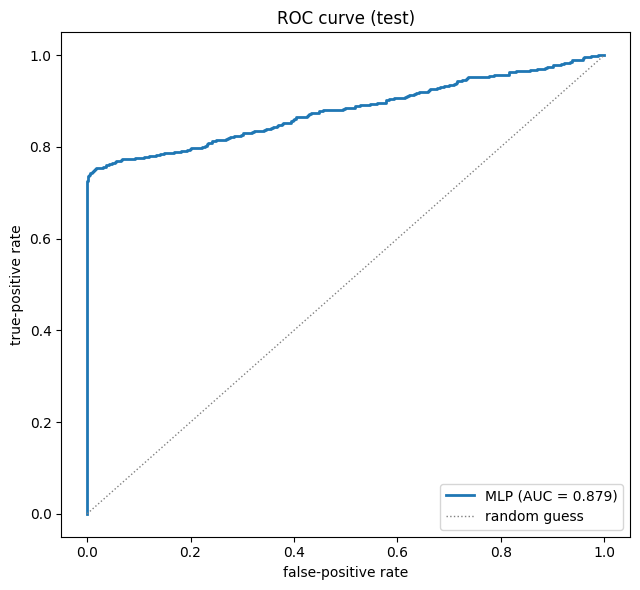

In [18]:
fpr, tpr, _ = roc_curve(y_test, mlp_prob)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, lw=2, label=f"MLP (AUC = {roc_auc_score(y_test, mlp_prob):.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":", lw=1, label="random guess")
ax.set_xlabel("false-positive rate")
ax.set_ylabel("true-positive rate")
ax.set_title("ROC curve (test)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### 14.2 Precision-recall curve
The PR curve focuses on the attack class: how much precision we keep as we try to catch more attacks. AP is the average precision (area under the curve).

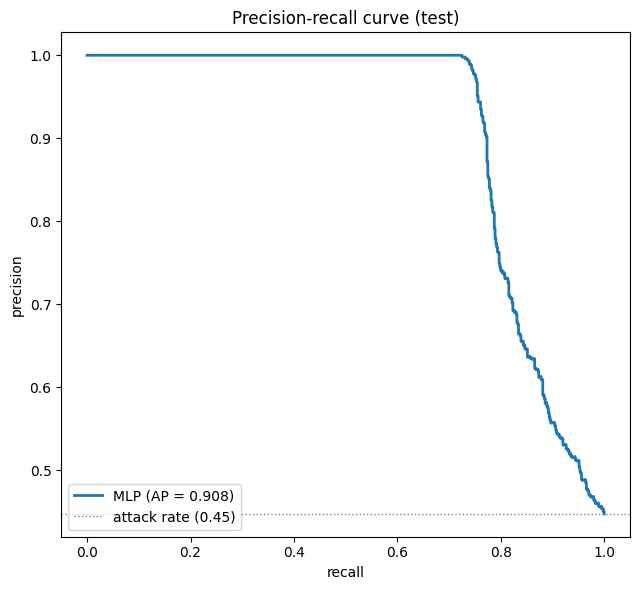

In [19]:
prec, rec, _ = precision_recall_curve(y_test, mlp_prob)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(rec, prec, lw=2, label=f"MLP (AP = {average_precision_score(y_test, mlp_prob):.3f})")
ax.axhline(y_test.mean(), color="grey", ls=":", lw=1, label=f"attack rate ({y_test.mean():.2f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-recall curve (test)")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

### 14.3 Confusion matrix (threshold 0.5)

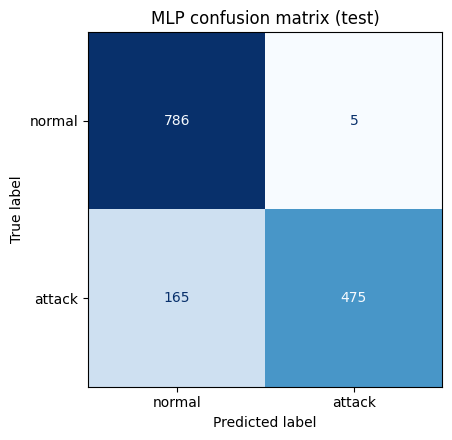

TN=786  FP=5  FN=165  TP=475


In [20]:
cm = confusion_matrix(y_test, mlp_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("MLP confusion matrix (test)")
fig.tight_layout()
plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

### Analysis

_(student analysis: what the curves and the confusion matrix show, and whether the model is effective)_

## 15. Export for the services
`save_artifacts` writes the trained weights (CPU copy), the fitted preprocessor and a small metadata file (version 1.0.0).
The test sessions are also saved in raw form (cleaned values, with `session_id` and the true label) so the web app can replay them as a live feed.
Finally the artifacts are loaded back with `Predictor`, exactly as the service does, and one session is scored as a sanity check.

In [21]:
model_cpu = copy.deepcopy(model).to("cpu").eval()  # a copy, so `model` stays on its device and section 14 can be re-run
save_artifacts(ARTIFACTS, model_cpu, pre, "1.0.0")
test_sessions = fill_missing_encryption(raw.loc[test_df.index])
test_sessions.to_csv(ARTIFACTS / "test_sessions.csv", index=False)
print("test_sessions.csv:", test_sessions.shape)
for f in sorted(ARTIFACTS.iterdir()):
    print(f"  {f.name:24s} {f.stat().st_size:>10,d} bytes")

predictor = Predictor.load(ARTIFACTS)
first = test_sessions[ORIGINAL_FEATURES].to_dict(orient="records")[0]
result = predictor.predict(Session(**first))
print("\nfirst test session:", first)
print("Predictor.predict  :", result)
print("notebook MLP prob  :", round(float(mlp_prob[0]), 6), "| true label:", int(test_sessions[TARGET].iloc[0]))
assert abs(result["probability"] - float(mlp_prob[0])) < 1e-5

test_sessions.csv: (1431, 11)
  metrics.csv                  14,295 bytes
  mlp.pt                       19,419 bytes
  model_meta.json                  57 bytes
  preprocess.joblib             3,564 bytes
  test_sessions.csv           108,036 bytes

first test session: {'network_packet_size': 621, 'login_attempts': 3, 'session_duration': 408.9554572142599, 'ip_reputation_score': 0.1166234324731716, 'failed_logins': 2, 'unusual_time_access': 0, 'protocol_type': 'ICMP', 'encryption_used': 'None', 'browser_type': 'Chrome'}
Predictor.predict  : {'probability': 0.18545719981193542, 'risk': 'Low', 'prediction': 0}
notebook MLP prob  : 0.185457 | true label: 0
